In [115]:
import time

import os

import matplotlib.pyplot as plt
import scipy.stats
import numpy as np
from scipy.stats import norm

import pywt

%load_ext autoreload
%autoreload 2

In [2038]:
spike_data = np.load("../../../data/birds/GreYel3594M/GreYel3594M___170915_082724/spikes/spike_waveforms-e6.npy")[()]

In [2039]:
spike_data

{'times': array([   26.46913333,    26.60706667,    26.8367    , ...,  5399.93613333,
         5399.9363    ,  5399.93853333]),
 'waveforms': array([[ 13.58842945,  -0.13929749,  -6.6104331 , ...,  23.30739975,
          24.22987747,  11.13924885],
        [  6.82815361,   2.55846071,  10.18618202, ...,  22.25850868,
          34.75062943,  34.23959351],
        [ 42.34589767,  20.9977417 ,  13.38947201, ...,  -8.52104282,
         -17.52228355, -26.0860424 ],
        ..., 
        [ 24.89542389,  18.1731472 ,  27.0004921 , ...,  49.09323883,
          28.72920227,   4.90428925],
        [-36.51329803, -27.06732178, -10.33838844, ..., -32.99253082,
         -11.3605957 ,  32.35777664],
        [  7.18568325,  15.93284607,  28.51374435, ..., -11.72331238,
          11.47726822,  20.53207397]])}

In [2040]:
spike_data["waveforms"].shape

(64346, 40)

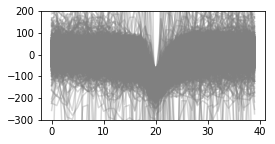

In [2041]:
plt.figure(figsize=(4, 2))
plt.plot(spike_data["waveforms"][:10000].T, color="Gray", alpha=0.3)
plt.ylim(-300, 200)
plt.show()

In [2042]:
original_waveforms = spike_data["waveforms"]


In [2043]:
decomp = pywt.wavedec(original_waveforms, 'haar', level=4)
original_waveforms_wavelet = np.hstack(decomp)
# waveforms_wavelet = PCA(n_components=16).fit_transform(waveforms)

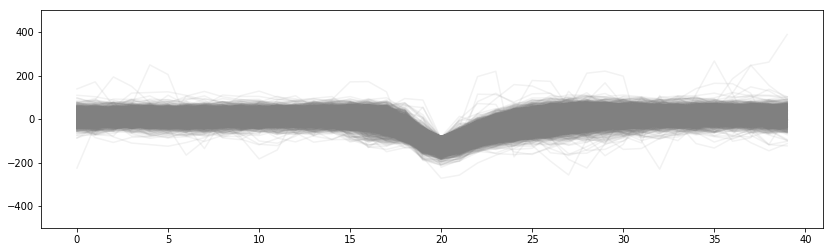

In [1363]:
plt.figure(figsize=(14, 4))
plt.plot(waveforms_wavelet.T, alpha=0.1, color="Gray")
plt.ylim(-500, 500)
plt.show()

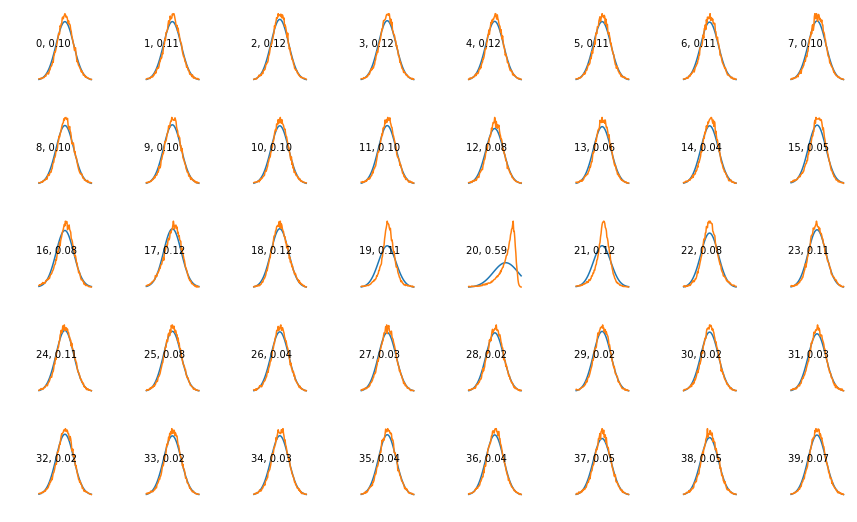

In [32]:
plt.figure(figsize=(12, 10))

use_feats = []
for i, feat in enumerate(waveforms.T):
    plt.subplot(7, 8, i + 1)
    m = np.mean(feat)
    s = np.std(feat)
    
    num_bins = 100
    counts, bin_edges = np.histogram(feat[(feat > (m - 3 * s)) & (feat < (m + 3 * s))],
                                        bins=num_bins, normed=True)
    cdf = np.cumsum(counts)

#     plt.plot(bin_edges[1:], norm.cdf(bin_edges[1:], loc=m, scale=s))
#     plt.plot(bin_edges[1:], cdf)
    

    plt.plot(bin_edges[1:], norm.pdf(bin_edges[1:], loc=m, scale=s))
    plt.plot(bin_edges[1:], counts)
    err = np.max(np.abs(norm.cdf(bin_edges[1:], loc=m, scale=s) - cdf))
    if err > 0.6: use_feats.append(i)
    plt.text(plt.xlim()[0], np.mean(plt.ylim()), "{}, {:.2f}".format(i, err))
#     plt.ylim()
    plt.axis("off")
    
plt.tight_layout()
plt.show()

In [1675]:
waveforms_wavelet = waveforms_wavelet[:, use_feats]

IndexError: index 16 is out of bounds for axis 1 with size 16

In [1366]:
waveforms_wavelet.shape

(4060, 40)

In [1367]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.manifold import TSNE

In [28]:
waveforms = waveforms[clusters == 0]

(33608, 41)


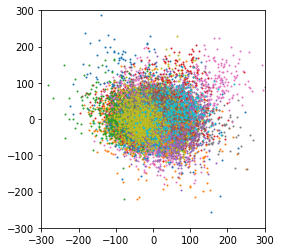

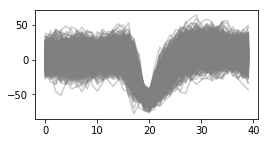

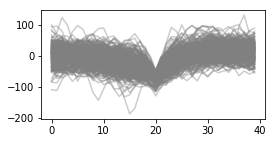

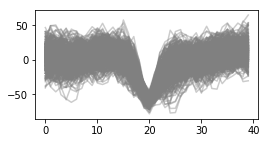

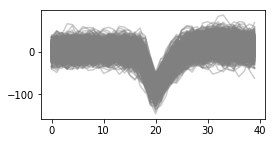

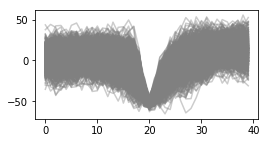

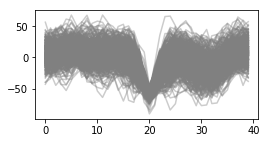

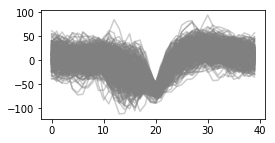

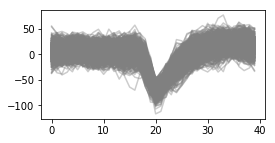

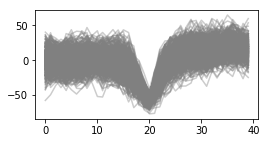

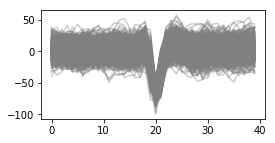

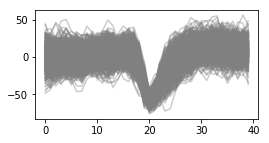

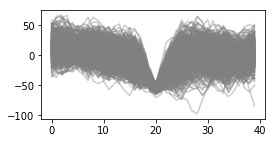

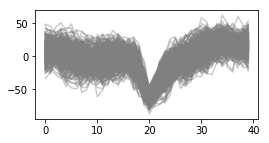

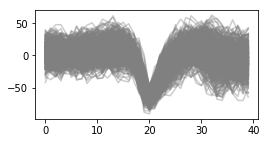

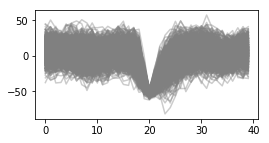

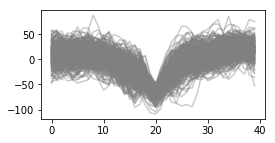

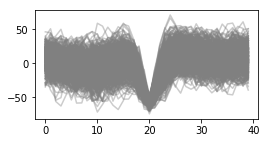

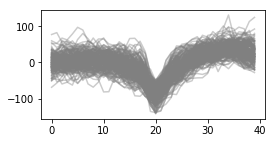

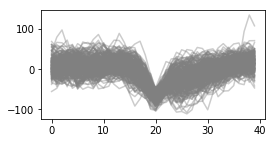

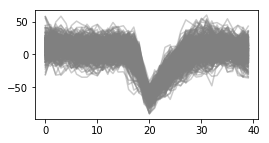

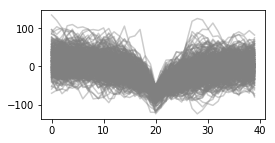

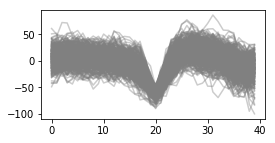

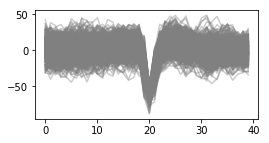

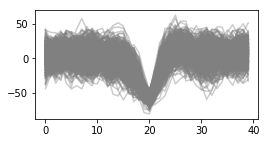

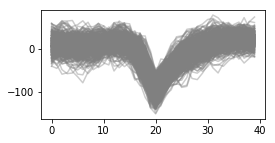

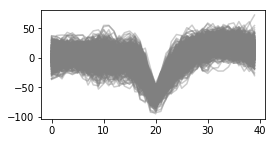

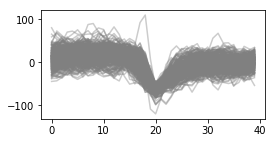

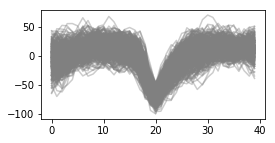

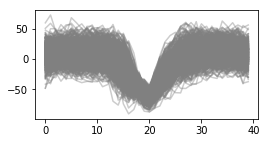

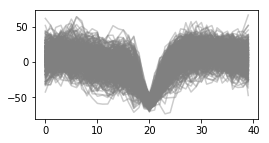

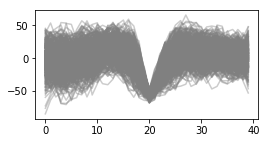

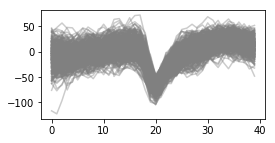

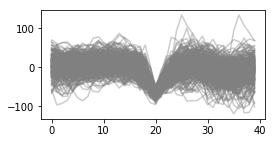

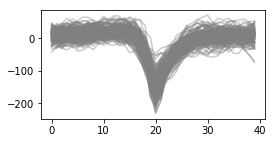

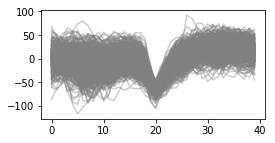

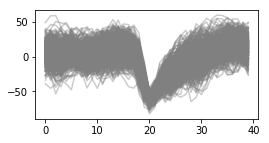

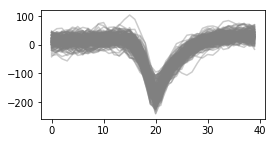

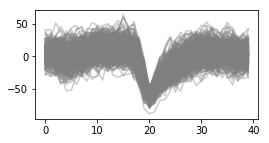

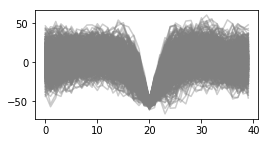

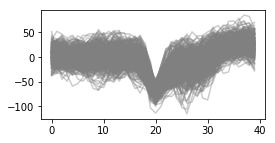

In [48]:
decomp = pywt.wavedec(waveforms, 'haar', level=4)
waveforms_wavelet = np.hstack(decomp)
print waveforms_wavelet.shape
use_feats = []
for i, feat in enumerate(waveforms.T):
    m = np.mean(feat)
    s = np.std(feat)

    num_bins = 100
    counts, bin_edges = np.histogram(feat[(feat > (m - 9 * s)) & (feat < (m + 9 * s))],
                                        bins=num_bins, normed=True)
    cdf = np.cumsum(counts)
    err = np.max(np.abs(norm.cdf(bin_edges[1:], loc=m, scale=s) - cdf))
    if err > 0.3: use_feats.append(i)

waveforms_wavelet = waveforms_wavelet[:, use_feats]

plt.figure(figsize=(4, 4))
data = PCA(n_components=2).fit_transform(waveforms_wavelet)
# mixtures = [GaussianMixture(n_components=n).fit(waveforms_wavelet) for n in range(1, 5)]
# best = np.argmin([mix.bic(waveforms_wavelet) for mix in mixtures])
# print [mix.bic(waveforms_wavelet) for mix in mixtures]
best = 0
mixtures = [GaussianMixture(n_components=40).fit(waveforms_wavelet)]
clusters = mixtures[best].predict(waveforms_wavelet)
probs = mixtures[best].predict_proba(waveforms_wavelet)
for cluster in np.unique(clusters):
    plt.scatter(*data[(clusters == cluster) & (probs[:, cluster] > 0.8)].T, s=1)
plt.xlim(-300, 300)
plt.ylim(-300, 300)
plt.show()
for cluster in np.unique(clusters):
    plt.figure(figsize=(4, 2))
    plt.plot(waveforms[(clusters == cluster) & (probs[:, cluster] > 0.8)][:1000].T, color="Gray", alpha=0.4)
    plt.show()

In [1368]:
from spikes.sorting.merging import *

from sklearn.lda import LDA as LDA

In [1404]:
original_clusters = KMeans(n_clusters=40).fit_predict(waveforms_wavelet)
clusters = original_clusters.copy()


In [1405]:
tracker = Tracker(np.unique(clusters))

In [1406]:
iso = IsoSplit(scale=2.0)

In [1407]:
data2d = PCA(n_components=2).fit_transform(waveforms_wavelet)

In [1944]:
def reassign(labels, data, projector, i, j, cutpoint):
    selector = (labels == i) | (labels == j)
#     label_data = data[selector]
    data_projected = projector.project(data)
    make_i = data_projected <= cutpoint
    make_j = data_projected > cutpoint
    labels[make_i & selector] = i
    labels[make_j & selector] = j
    return labels


def reassign(labels, data, projector, i, j, cutpoint):
    """KMeans version"""
    selector = (labels == i) | (labels == j)
#     label_data = data[selector]
    new_labels = KMeans(n_clusters=2).fit(data[selector]).predict(data)
#     new_labels = GaussianMixture(n_components=2).fit(data[selector]).predict(data)
    labels[selector & (new_labels == 0)] = i
    labels[selector & (new_labels == 1)] = j
    return labels

In [1489]:
class Projector(object):

    def __init__(self):
        self.lda = LDA(n_components=2)
        
    def fit_transform(self, data, labels, i, j):
        selector = (labels == i) | (labels == j)
        self.projected = self.lda.fit_transform(data[selector], labels[selector])[:, 0]
        self.original_x = self.projected[labels[selector] == i]
        self.original_y = self.projected[labels[selector] == j]

    def project(self, data, ndim=1):
        if ndim == 1:
            return self.lda.transform(data)[:, 0]
        else:
            return self.lda.transform(data)


## Iso split algorithm

### First, compute the means of all clusters, and sort the cluster pairs by the most nearby-est ones

In [1676]:
means = compute_means(waveforms_wavelet, clusters)
# print tracker.pairs(sorter=means)

In [1677]:
first_pair = tuple(tracker.pairs(sorter=means)[0])
print first_pair

IndexError: list index out of range

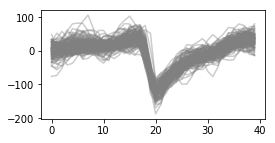

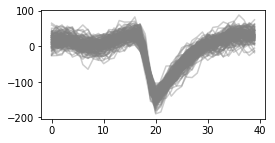

In [1464]:
for cluster in first_pair:
    plt.figure(figsize=(4, 2))
    plt.plot(waveforms[(clusters == cluster)][:1000].T, color="Gray", alpha=0.4)
    plt.show()

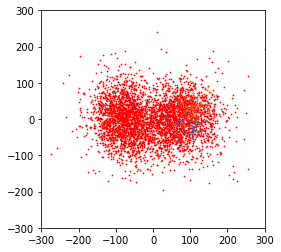

In [1465]:
plt.figure(figsize=(4, 4))
plt.scatter(*data2d[:10000].T, s=0.5, alpha=1.0, color="Red")
for cluster in first_pair:
    plt.scatter(*data2d[(clusters == cluster)].T, s=0.1)
plt.xlim(-300, 300)
plt.ylim(-300, 300)
plt.show()


### Next, project them onto the line dividing the two means

In [1466]:
# proj = Projector(*[
#     np.mean(waveforms_wavelet[clusters==cluster], axis=0) for cluster in first_pair
# ])
# x_projected = [
#     proj.project(waveforms_wavelet[clusters == cluster]) for cluster in first_pair
# ]

# x = np.concatenate(x_projected)

# selector = (clusters == first_pair[0]) | (clusters == first_pair[1])
# x = LDA(n_components=1).fit_transform(waveforms_wavelet[selector], clusters[selector]).flatten()
# x_projected = [
#     x[clusters[selector] == first_pair[0]],
#     x[clusters[selector] == first_pair[1]]
# ]

In [1467]:
proj = Projector()
proj.fit_transform(waveforms_wavelet, clusters, *first_pair)
x = proj.projected
x_projected = [proj.original_x, proj.original_y]


In [1468]:
k, cutpoint, xsub, a, b = iso.isocut(x)

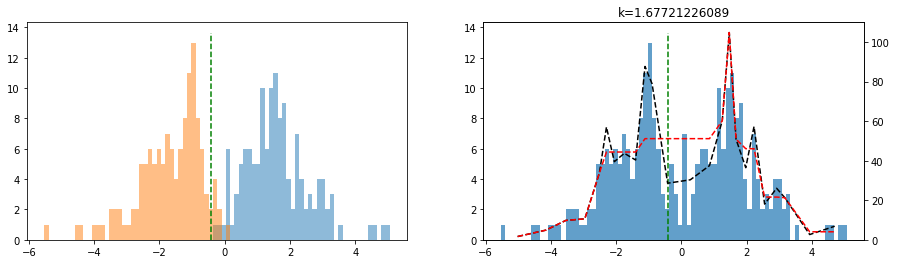

In [1478]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 2, 2)
bins, bin_edges, _ = plt.hist(x, bins=80, alpha=0.7)
plt.vlines(cutpoint, *plt.ylim(), linestyle="--", color="Green")
plt.title("k={}".format(k))
plt.gca().twinx()
plt.plot(xsub, b, color="Black", linestyle="--")
plt.plot(xsub, a, color="Red", linestyle="--")
plt.ylim(0, plt.ylim()[1])


plt.subplot(1, 2, 1)
plt.hist(x_projected[0], bins=bin_edges, alpha=0.5)
plt.hist(x_projected[1], bins=bin_edges, alpha=0.5)

plt.vlines(cutpoint, *plt.ylim(), linestyle="--", color="Green")

plt.show()

### If the two clusters are unimodal... (k < threshold) merge them

Otherwise, just mark it as checked

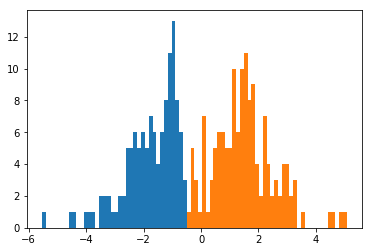

In [1484]:
selector = (clusters == first_pair[0]) | (clusters == first_pair[1])
#     label_data = data[selector]
data_projected = proj.project(waveforms_wavelet)
make_i = data_projected <= cutpoint
make_j = data_projected > cutpoint
plt.hist(data_projected[make_i & selector], bins=bin_edges)
plt.hist(data_projected[make_j & selector], bins=bin_edges)
plt.show()

In [1485]:
if k < 1.0:
    clusters = merge(clusters, *first_pair)
    tracker.touch(first_pair[0])
    tracker.remove(first_pair[1])
else:
    clusters = reassign(clusters, waveforms_wavelet, proj, first_pair[0], first_pair[1], cutpoint)
    tracker.touch(first_pair[0])
    tracker.touch(first_pair[1])
tracker.check(first_pair)


In [1447]:
%debug

> <ipython-input-1440-ea3c83cec2c8>(6)reassign()
      4     make_i = data_projected <= cutpoint
      5     make_j = data_projected > cutpoint
----> 6     labels[make_i & label_data] = i
      7     labels[make_j & label_data] = j
      8     return labels

ipdb> make_i.shape
(237,)
ipdb> label_data.shape
(237, 40)
ipdb> exit


### Err... are any going to come out as unimodal?

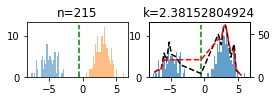

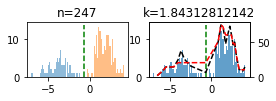

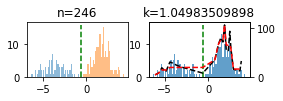

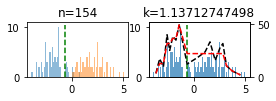

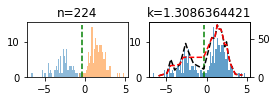

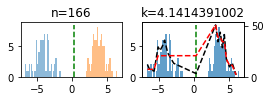

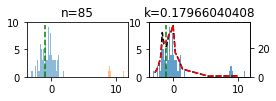

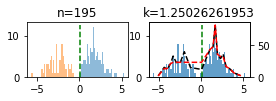

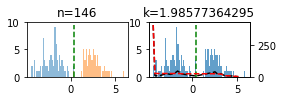

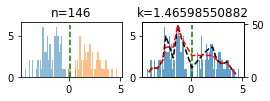

In [1486]:
for pair in tracker.pairs()[:10]:
    pair = tuple(pair)
    selector = (clusters == pair[0]) | (clusters == pair[1])
    x = LDA(n_components=1).fit_transform(waveforms_wavelet[selector], clusters[selector]).flatten()
    x_projected = [
        x[clusters[selector] == pair[0]],
        x[clusters[selector] == pair[1]]
    ]
    k, cutpoint, xsub, a, b = iso.isocut(x)
    plt.figure(figsize=(4, 1))

    plt.subplot(1, 2, 2)
    bins, bin_edges, _ = plt.hist(x, bins=80, alpha=0.7)
    plt.vlines(cutpoint, *plt.ylim(), linestyle="--", color="Green")
    plt.title("k={}".format(k))
    plt.gca().twinx()
    plt.plot(xsub, b, color="Black", linestyle="--")
    plt.plot(xsub, a, color="Red", linestyle="--")
    plt.ylim(0, plt.ylim()[1])


    plt.subplot(1, 2, 1)
    plt.hist(x_projected[0], bins=bin_edges, alpha=0.5)
    plt.hist(x_projected[1], bins=bin_edges, alpha=0.5)

    plt.vlines(cutpoint, *plt.ylim(), linestyle="--", color="Green")
    plt.title("n={}".format(len(x)))
    plt.show()

### Lets try the algo without cluster reassignment

In [1503]:
def proj(x, y, ndim=1):
    labels = np.concatenate([np.zeros(len(x)), np.ones(len(y))])
    labels[0] = 2
    total_x = np.vstack([x, y])
    result = LDA(n_components=ndim).fit_transform(total_x, labels)
    if ndim == 1:
        return result.flatten()
    return result

In [2155]:
def reassign(labels, data, projector, i, j, cutpoint):
    selector = (labels == i) | (labels == j)
#     label_data = data[selector]
    data_projected = projector.project(data)
    make_i = data_projected <= cutpoint
    make_j = data_projected > cutpoint
    labels[make_i & selector] = i
    labels[make_j & selector] = j
    return labels


def reassign(labels, data, projector, i, j, cutpoint):
    """KMeans version"""
    selector = (labels == i) | (labels == j)
#     label_data = data[selector]
#     new_labels = KMeans(n_clusters=2).fit(data[selector]).predict(data)
    new_labels = GaussianMixture(n_components=2).fit(data[selector]).predict(data)
    labels[selector & (new_labels == 0)] = i
    labels[selector & (new_labels == 1)] = j
    return labels


def reassign(labels, data, projector, i, j, cutpoint):
    selector = (labels == i) | (labels == j)
#     label_data = data[selector]
    data_projected = projector.project(data)
    
#     new_labels = GaussianMixture(n_components=2).fit(data_projected[selector, None]).predict(data_projected[:, None])
    new_labels = KMeans(n_clusters=2).fit(data_projected[selector, None]).predict(data_projected[:, None])
    labels[selector & (new_labels == 0)] = i
    labels[selector & (new_labels == 1)] = j
    return labels



In [2174]:
# original_clusters.copy()[:2000]
slice_of_life = slice(0, -1)

waveforms = original_waveforms.copy()[slice_of_life, 14:30]

peaks = waveforms[:, 6]
waveforms = waveforms[(peaks < -60) & (peaks > -600)]   # CLEAN IT UP TO THE BIGGEST SPIKES???
# waveforms_wavelet = original_waveforms_wavelet.copy()[slice_of_life]
waveforms_wavelet = waveforms
data2d = PCA(n_components=2).fit_transform(waveforms)
# clusters = KMeans(n_clusters=30, n_jobs=8).fit_predict(waveforms)
clusters = GaussianMixture(n_components=20).fit(waveforms).predict(waveforms)

tracker = Tracker(np.unique(clusters))
iso = IsoSplit(scale=4.0)
threshold = 0.4

In [2175]:
tokeep = np.ones_like(clusters)
for clust, count in zip(*np.unique(clusters, return_counts=True)):
    if count < len(waveforms_wavelet) // 100:
        tokeep[clusters == clust] = 0
tokeep = tokeep.astype(bool)

waveforms = waveforms[tokeep]
waveforms_wavelet = waveforms_wavelet[tokeep]
clusters = clusters[tokeep]
data2d = data2d[tokeep]
tracker = Tracker(np.unique(clusters))


In [2176]:
np.unique(clusters, return_counts=True)

(array([ 0,  1,  5,  6,  8,  9, 10, 11, 13, 15, 16]),
 array([ 2994,  6331,  4128, 13092,  9516,  1962,  3995,  5584,  4735,
          971,  8330]))

In [2177]:
tracker = Tracker(np.unique(clusters))

initial_clust = len(np.unique(clusters))


In [2178]:
DO_PRINT = False

In [2179]:
last_cluster_count = initial_clust
stuck_here_for_a_while = 0
while tracker.pairs():
    means = compute_means(waveforms_wavelet, clusters)

    i, j = tuple(tracker.pairs(sorter=means)[0])
#     samp = np.random.choice(np.arange(len(tracker.pairs())))
    threshold = 0.1 + 0.6 * len(np.unique(clusters)) / float(initial_clust)
#     i, j = tracker.pairs(sorter=means)[samp]
    try:
#         projected = proj(waveforms_wavelet[clusters == i], waveforms_wavelet[clusters == j], ndim=1)
#         proj_2d = proj(waveforms_wavelet[clusters == i], waveforms_wavelet[clusters == j], ndim=2)
#         proji = proj_2d[:len(waveforms_wavelet[clusters == i])]
#         projj = proj_2d[len(waveforms_wavelet[clusters == i]):]
        
        proj = Projector()
        proj.fit_transform(waveforms_wavelet, clusters, i, j)
        projected = proj.projected
        proji = proj.original_x
        projj = proj.original_y
        proj2d = proj.project(waveforms_wavelet[(clusters == i) | (clusters == j)])

    except ZeroDivisionError:
        k = 0.0
        cutpoint = None
        xsub = None
        a = b = None
    else:
        k, cutpoint, xsub, a, b = iso.isocut(projected)

    if cutpoint and DO_PRINT:
        plt.figure(figsize=(16, 2))
        plt.subplot(1, 5, 1)
        bins, bin_edges, _ = plt.hist(projected, bins=80, alpha=0.7)
        plt.title("k={}".format(k))
        plt.vlines(cutpoint, *plt.ylim(), linestyle="--", color="Green")

        if k > threshold:
            plt.axis("off")

        plt.gca().twinx()
        plt.plot(xsub, b, color="Black", linestyle="--")
        plt.plot(xsub, a, color="Red", linestyle="--")
        plt.ylim(0, plt.ylim()[1])
        if k > threshold:
            plt.axis("off")

        plt.subplot(1, 5, 2)
#         try:
#             plt.scatter(*proji.T, s=1, alpha=0.5)
#             plt.scatter(*projj.T, s=1, alpha=0.5)
#         except:
#             pass
        
#         plt.subplot(1, 2, 2)
        plt.hist(proji, bins=bin_edges, alpha=0.5)
        plt.hist(projj, bins=bin_edges, alpha=0.5)

        if k > threshold:
            plt.vlines(cutpoint, *plt.ylim(), linestyle="--", color="Green")

        plt.axis("off")
        
        if k < threshold:
            plt.subplot(1, 5, 3)
            for cluster in [i, j]:
                plt.scatter(*data2d[(clusters == cluster)].T, s=1, alpha=0.5)
            plt.axis("off")

            plt.subplot(1, 5, 4)
            plt.plot(waveforms[(clusters == i)][:1000].T, color="Gray", alpha=0.4)
            plt.ylim(-300, 200)
            plt.xlim(-6, 22)
            plt.axis("off")

            plt.subplot(1, 5, 5)
            plt.plot(waveforms[(clusters == j)][:1000].T, color="Gray", alpha=0.4)
            plt.ylim(-300, 200)
            plt.xlim(-6, 22)
            plt.axis("off")

            plt.show()

    elif not cutpoint:
        print "how did you do this"
        

    if k < threshold and k != 0:
        clusters = merge(clusters, i, j)
        tracker.touch(i)
        tracker.remove(j)
        tracker.check([i, j])
    elif k >= threshold:
        clusters = reassign(clusters, waveforms_wavelet, proj, i, j, cutpoint)
        tracker.touch(i)
        tracker.touch(j)
        tracker.check([i, j])
    else:
        tracker.check([i, j])
        
    if len(np.unique(clusters)) == last_cluster_count:
        stuck_here_for_a_while += 1
        if stuck_here_for_a_while >= last_cluster_count ** 2:
            print "stuck on {} for {} iters".format(last_cluster_count, stuck_here_for_a_while)
            break
    else:
        last_cluster_count = len(np.unique(clusters))
        stuck_here_for_a_while = 0
        
    if cutpoint and k >= threshold and DO_PRINT:
        plt.subplot(1, 5, 3)
        for cluster in [i, j]:
            plt.scatter(*data2d[(clusters == cluster)].T, s=1, alpha=0.5)
        plt.title("After reassignment now")
        plt.axis("off")

        plt.subplot(1, 5, 4)
        plt.plot(waveforms[(clusters == i)][:1000].T, color="Gray", alpha=0.4)
        plt.ylim(-300, 200)
        plt.xlim(-6, 22)
        plt.axis("off")

        plt.subplot(1, 5, 5)
        plt.plot(waveforms[(clusters == j)][:1000].T, color="Gray", alpha=0.4)
        plt.ylim(-300, 200)
        plt.xlim(-6, 22)
        plt.axis("off")

        plt.show()


stuck on 3 for 9 iters


In [2180]:
np.unique(clusters)

array([ 0, 11, 16])

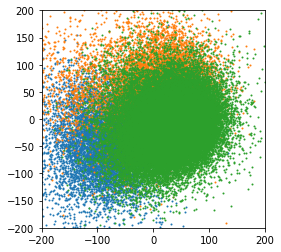

In [2181]:
plt.figure(figsize=(4, 4))
# mixtures = [GaussianMixture(n_components=n).fit(waveforms_wavelet) for n in range(1, 5)]
# best = np.argmin([mix.bic(waveforms_wavelet) for mix in mixtures])
# print [mix.bic(waveforms_wavelet) for mix in mixtures]
best = 0
for cluster in np.unique(clusters):
    plt.scatter(*data2d[(clusters == cluster)].T, s=1)
plt.xlim(-200, 200)
plt.ylim(-200, 200)
plt.show()
# for cluster in np.unique(clusters):
#     plt.figure(figsize=(3, 3))
#     plt.plot(waveforms[(clusters == cluster)][:2000].T, color="Gray", alpha=0.4)
#     plt.ylim(-300, 200)
#     plt.show()

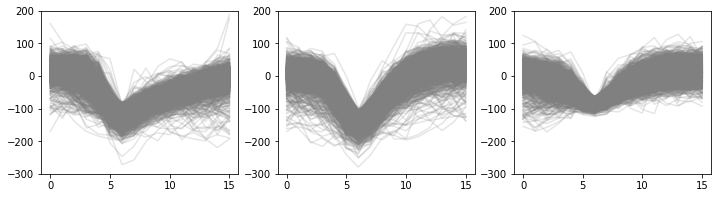

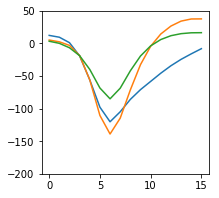

In [2182]:
plt.figure(figsize=(12, 3))
for i, cluster in enumerate(np.unique(clusters)):
    plt.subplot(1, len(np.unique(clusters)), i+1)
    plt.plot(waveforms[(clusters == cluster)][:2000].T, color="Gray", alpha=0.2)
    plt.ylim(-300, 200)
plt.show()

plt.figure(figsize=(3, 3))
for i, cluster in enumerate(np.unique(clusters)):
    plt.plot(np.mean(waveforms[(clusters == cluster)], axis=0))
    plt.ylim(-200, 50)
plt.show()



In [1643]:
%debug

> /auto/fhome/kevin/Projects/songephys/env/local/lib/python2.7/site-packages/sklearn/mixture/gaussian_mixture.py(412)_estimate_log_gaussian_prob()
    410         log_prob = np.empty((n_samples, n_components))
    411         for k, (mu, prec_chol) in enumerate(zip(means, precisions_chol)):
--> 412             y = np.dot(X, prec_chol) - np.dot(mu, prec_chol)
    413             log_prob[:, k] = np.sum(np.square(y), axis=1)
    414 

ipdb> exit


In [570]:
plt.clf()

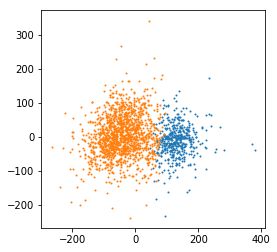

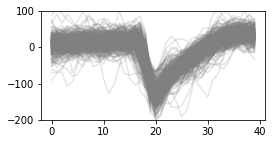

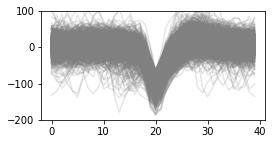

In [1294]:
plt.figure(figsize=(4, 4))
clusters = labels
for cluster in np.unique(clusters):
    plt.scatter(*data[clusters == cluster].T, s=1)
plt.show()
for cluster in np.unique(clusters):
    plt.figure(figsize=(4, 2))
    plt.plot(waveforms[clusters == cluster].T, color="Gray", alpha=0.2)
    plt.ylim(-200, 100)
    plt.show()

In [1300]:
waveforms_wavelet[labels == 1]

array([[  17.21993583,  -42.69295825,  -12.91576348, ...,   -9.44196943,
          14.29494033,  -27.53674641],
       [  89.00701929,  -86.79399826,   20.14824696, ...,    0.75438181,
          32.88345649,   -7.04829593],
       [  59.7858302 ,  -38.90394463,  -24.12651365, ...,    8.07233527,
          16.19414471,  -14.76416109],
       ..., 
       [   9.95721858,  -75.74897509,  -46.95593153, ...,  -20.86971126,
         -23.69233874,  -11.26078983],
       [  77.66400641,  -12.77733224,  -23.77036393, ...,  -14.52367032,
         -10.57474208,   -6.28629753],
       [ 113.34671145,    7.87312004,  -20.06851611, ...,  -25.52221319,
         -35.40281051,  -13.32269301]])

In [1302]:
def reorganize(labels):
    result = np.zeros(len(labels))

    old_labels = np.sort(np.unique(labels))
    new_labels = np.arange(len(old_labels))

    for new, old in zip(new_labels, old_labels):
        result[labels == old] = new

    return result        

In [1305]:
def compute_means(data, labels):
    return dict(
        (label, np.mean(data[labels == label], axis=0)) for label in np.unique(labels)
    )

In [1405]:
def dist(label1, label2, means=None):
    try:
        return np.linalg.norm(means[label2] - means[label1])
    except:
        return np.inf

In [1371]:
means = compute_means(waveforms_wavelet, labels)
pairs = [{label1, label2} for label1 in np.unique(labels) for label2 in np.unique(labels) if label1 < label2]
pairs.sort(key=lambda x: dist(*list(x), means=means))
pairs = filter(lambda x: tuple(sorted(x)) not in checked, pairs)

In [1419]:
def merge(labels, label1, label2):
    labels[labels == label2] = label1
    return labels

In [1353]:
checked = set()

In [1419]:
class Tracker(object):
    def __init__(self, unique_labels):
        self.unique_labels = unique_labels
        self.checked = []
    
    def pairs(self, sorter=None):
        pairs = [
            {label1, label2}
            for label1 in self.unique_labels
            for label2 in self.unique_labels
            if label1 < label2
            and set([label1, label2]) not in self.checked
        ]
        if sorter is not None:
            return sorted(pairs, key=lambda x: dist(*list(x), means=sorter))
        else:
            return pairs
        
    def touch(self, label):
        self.checked = filter(lambda x: label not in x, self.checked)
        
    def remove(self, label):
        self.unique_labels = filter(lambda x: x != label, self.unique_labels)
    
    def check(self, pair):
        # free up this to be checked again
        self.checked.append(set(pair))

In [1420]:
tracker = Tracker(np.unique(labels))

In [1421]:
tracker.pairs(sorter=means)

[{2, 3},
 {0, 17},
 {1, 15},
 {0, 16},
 {3, 12},
 {6, 19},
 {8, 19},
 {3, 19},
 {3, 9},
 {5, 19},
 {13, 19},
 {5, 13},
 {2, 12},
 {2, 9},
 {1, 9},
 {3, 5},
 {8, 13},
 {9, 14},
 {2, 19},
 {12, 13},
 {2, 5},
 {5, 9},
 {1, 5},
 {8, 9},
 {5, 6},
 {1, 8},
 {9, 19},
 {12, 14},
 {5, 8},
 {6, 11},
 {0, 4},
 {3, 14},
 {9, 12},
 {12, 19},
 {1, 19},
 {3, 13},
 {16, 17},
 {2, 14},
 {2, 13},
 {6, 13},
 {1, 3},
 {2, 4},
 {9, 15},
 {0, 14},
 {8, 12},
 {0, 3},
 {3, 18},
 {6, 8},
 {3, 4},
 {4, 13},
 {4, 12},
 {1, 13},
 {3, 15},
 {8, 11},
 {11, 13},
 {0, 12},
 {3, 8},
 {14, 15},
 {12, 15},
 {2, 8},
 {9, 13},
 {5, 12},
 {7, 9},
 {14, 17},
 {0, 2},
 {1, 6},
 {7, 14},
 {1, 12},
 {4, 16},
 {5, 11},
 {11, 19},
 {2, 18},
 {2, 6},
 {1, 2},
 {3, 6},
 {7, 12},
 {8, 15},
 {5, 18},
 {1, 11},
 {7, 15},
 {5, 14},
 {15, 19},
 {9, 18},
 {4, 19},
 {4, 5},
 {1, 14},
 {0, 15},
 {5, 15},
 {6, 9},
 {12, 17},
 {14, 18},
 {13, 15},
 {7, 8},
 {3, 17},
 {4, 14},
 {0, 18},
 {4, 17},
 {14, 19},
 {2, 15},
 {13, 14},
 {8, 14},
 {1

In [1877]:
waveforms = wf_list[6]
waveforms_wavelet = waveforms # WaveletFeatures().fit_transform(waveforms)
# waveforms_wavelet = PCA(n_components=20).fit_transform(waveforms)
data = PCA(n_components=2).fit_transform(waveforms_wavelet)

In [1874]:
kmeans = KMeans(n_clusters=16)
labels = kmeans.fit_predict(waveforms_wavelet)

In [1875]:
tracker = Tracker(np.unique(labels))
threshold = 1.0
while tracker.pairs():
    means = compute_means(waveforms_wavelet, labels)
    i, j = tuple(tracker.pairs(sorter=means)[0])
    
    res = compare_2_clusters(waveforms_wavelet[labels==i], waveforms_wavelet[labels==j])
    k, split, true, fitted = isocut(waveforms_wavelet[labels==i], waveforms_wavelet[labels==j])

    if k < threshold:
        labels = merge(labels, i, j)
        tracker.touch(i)
        tracker.remove(j)
        tracker.check([i, j])
    else:
        tracker.check([i, j])


250
(23,)
(23,)
385
(28,)
(28,)
220
(21,)
(21,)
472
(31,)
(31,)
289
(24,)
(24,)
295
(25,)
(25,)
435
(30,)
(30,)
575
(34,)
(34,)
700
(38,)
(38,)
842
(42,)
(42,)
974
(45,)
(45,)
455
(31,)
(31,)
542
(33,)
(33,)
598
(35,)
(35,)
1194
(49,)
(49,)
1244
(50,)
(50,)
1842
(61,)
(61,)


1842


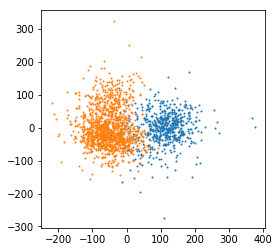

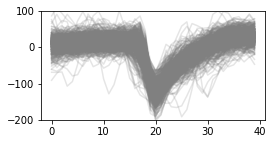

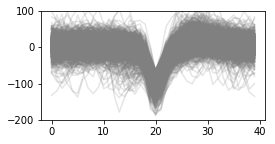

In [1876]:
plt.figure(figsize=(4, 4))
print len(labels)
clusters = labels
for cluster in np.unique(clusters):
    plt.scatter(*data[clusters == cluster].T, s=1)
plt.show()
for cluster in np.unique(clusters):
    plt.figure(figsize=(4, 2))
    plt.plot(waveforms[clusters == cluster].T, color="Gray", alpha=0.2)
    plt.ylim(-200, 100)
    plt.show()

In [1638]:
## Feature space
## Algorithm

In [15]:
from spikes.sorting.merging import isosplit_cluster

In [16]:
%load_ext autoreload
%autoreload 2

In [20]:
waveforms = wf_list[5]
decomp = pywt.wavedec(waveforms, 'haar', level=4)
waveforms_wavelet = np.hstack(decomp)
waveforms_wavelet = PCA(n_components=20).fit_transform(waveforms)
data = PCA(n_components=2).fit_transform(waveforms_wavelet)

In [21]:
labels = isosplit_cluster(waveforms, threshold=1.0, k_initial=30)

498


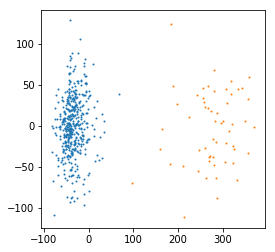

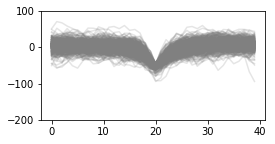

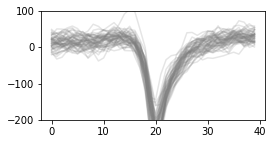

In [22]:
plt.figure(figsize=(4, 4))
print len(labels)
clusters = labels
for cluster in np.unique(clusters):
    plt.scatter(*data[clusters == cluster].T, s=1)
plt.show()
for cluster in np.unique(clusters):
    plt.figure(figsize=(4, 2))
    plt.plot(waveforms[clusters == cluster].T, color="Gray", alpha=0.2)
    plt.ylim(-200, 100)
    plt.show()